This notebook shows the design of the database of a fictionl store.

In [92]:
#Installing Jupysql
%pip install jupysql


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [93]:
%load_ext sql

The sql extension is already loaded. To reload it, use:
  %reload_ext sql


In [94]:
%sql sqlite:///customDb.db

In [95]:
%config SqlMagic.displaylimit = None

displaylimit: Value None will be treated as 0 (no limit)

In [96]:
%%sql
# Turning foreigh keys since this sqllite
PRAGMA foreign_keys = ON;

Running query in 'sqlite:///customDb.db'

++
||
++
++

In [97]:

%%sql
# testing

SELECT 1+1 AS test_table;

Running query in 'sqlite:///customDb.db'

test_table
2


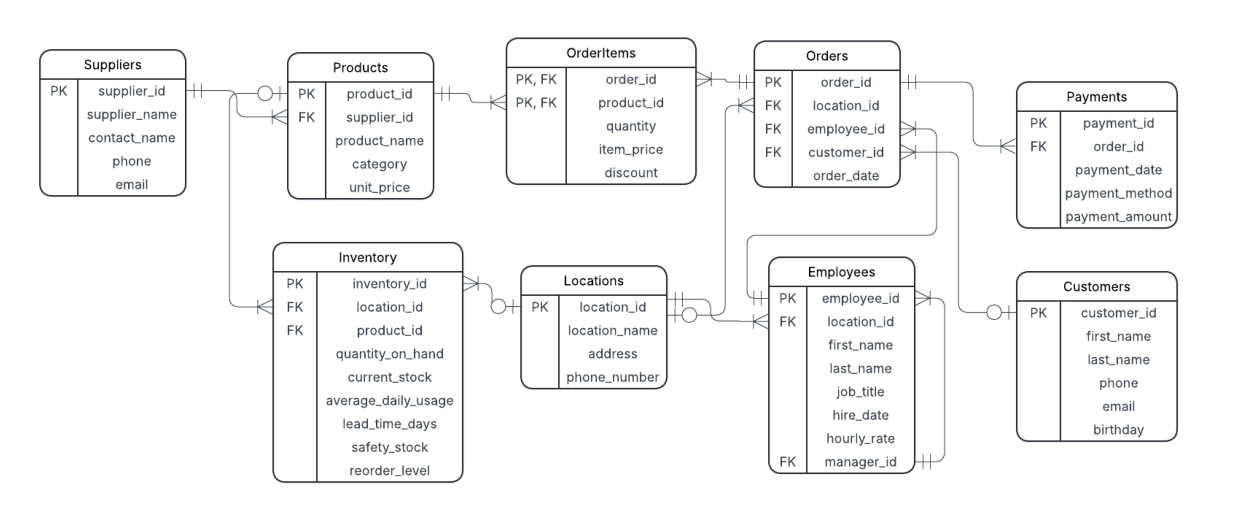

In [98]:
# ER Diagram
import matplotlib.pyplot as plt
import matplotlib.image as mpltimg

img = mpltimg.imread("JLN ER Diagram.png")
plt.figure(figsize=(16, 9))
plt.imshow(img)
plt.axis('off')
plt.show()

In [99]:
%%sql

-- DDL
-- Creating the tables

DROP TABLE IF EXISTS Payments;
DROP TABLE IF EXISTS OrderItems;
DROP TABLE IF EXISTS Orders;
DROP TABLE IF EXISTS Inventory;
DROP TABLE IF EXISTS Customers;
DROP TABLE IF EXISTS Products;
DROP TABLE IF EXISTS Employees;
DROP TABLE IF EXISTS Suppliers;
DROP TABLE IF EXISTS Locations;

# 1. Locations Table

CREATE TABLE Locations (
    location_id INTEGER PRIMARY KEY,
    location_name TEXT NOT NULL,
    address TEXT,
    phone_number TEXT 
);

# 2. Suppliers Table

CREATE TABLE Suppliers (
    supplier_id INTEGER PRIMARY KEY,
    supplier_name TEXT NOT NULL,
    contact_name TEXT,
    phone TEXT,
    email TEXT
);

# 3. Employees Table

CREATE TABLE Employees (
    employee_id INTEGER PRIMARY KEY,
    location_id INTEGER,
    first_name TEXT,
    last_name TEXT,
    job_title TEXT,
    hire_date DATE,
    hourly_rate DECIMAL(10, 2),
    manager_id INTEGER,
    FOREIGN KEY (location_id) REFERENCES Locations(location_id),
    FOREIGN KEY (manager_id) REFERENCES Employees (employee_id)
);

# 4. Product Table

CREATE TABLE Products (
    product_id INTEGER PRIMARY KEY,
    supplier_id INTEGER,
    product_name TEXT NOT NULL,
    category TEXT,
    unit_price DECIMAL(10, 2),
    FOREIGN KEY (supplier_id) REFERENCES Suppliers(supplier_id)
);

# 5. Customers Table

CREATE TABLE Customers (
    customer_id INTEGER PRIMARY KEY,
    first_name TEXT NOT NULL,
    last_name TEXT NOT NULL,
    phone TEXT,
    email TEXT,
    birthday DATE
);

# 6. Inventory Table

CREATE TABLE Inventory (
    inventory_id INTEGER PRIMARY KEY,
    location_id INTEGER,
    product_id INTEGER,
    quantity_on_hand INTEGER DEFAULT 0, # 0: good, 1:bad
    current_stock INTEGER, # real time quantity on hand
    average_daily_usage INTEGER, # avg units sold daily
    lead_time_days INTEGER, # time taken by supplier for delivery
    safety_stock INTEGER, # buffer stock to prevent stockout
    reorder_level INTEGER, # (daily usage * lead time) + safety shock
    FOREIGN KEY (location_id) REFERENCES Locations(location_id),
    FOREIGN KEY (product_id) REFERENCES Products(product_id)
);

# 7. Orders Table

CREATE TABLE Orders (
    order_id INTEGER PRIMARY KEY,
    location_id INTEGER,
    employee_id INTEGER,
    customer_id INTEGER,
    order_date DATE,
    FOREIGN KEY (location_id) REFERENCES Locations(location_id),
    FOREIGN KEY (employee_id) REFERENCES Employees(employee_id),
    FOREIGN KEY (customer_id) REFERENCES Customers(customer_id)
);

# 8. OrderItems Table

CREATE TABLE OrderItems (
    order_id INTEGER,
    product_id INTEGER,
    quantity INTEGER NOT NULL,
    item_price DECIMAL(10, 2),
    discount DECIMAL(5, 2) DEFAULT 0.00,
    PRIMARY KEY (order_id, product_id),
    FOREIGN KEY (order_id) REFERENCES Orders(order_id),
    FOREIGN KEY (product_id) REFERENCES Products(product_id)
);

# 9. Payments Table

CREATE TABLE Payments (
    payment_id INTEGER PRIMARY KEY,
    order_id INTEGER,
    payment_date DATE,
    payment_method TEXT,
    payment_amount DECIMAL(10, 2),
    FOREIGN KEY (order_id) REFERENCES Orders(order_id)
);

Running query in 'sqlite:///customDb.db'

++
||
++
++

In [100]:
%%sql
# Testing on one table

SELECT *
FROM Payments;

Running query in 'sqlite:///customDb.db'

payment_id,order_id,payment_date,payment_method,payment_amount


In [101]:
%%sql 
# Adding one record to the Customers Table

DELETE  FROM Customers;

INSERT INTO Customers(first_name, last_name, phone, email, birthday)
VALUES
('Joshua', 'Perry', 12345678, 'jperry@gmail.com', '1960-08-23'),
('Paola', 'McGale', 62345678, 'pmcgale@gmail.com', '1990-04-13');

SELECT *
FROM Customers;

Running query in 'sqlite:///customDb.db'

2 rows affected.

customer_id,first_name,last_name,phone,email,birthday
1,Joshua,Perry,12345678,jperry@gmail.com,1960-08-23
2,Paola,McGale,62345678,pmcgale@gmail.com,1990-04-13


In [102]:
%%sql
# Testing query
SELECT CONCAT(first_name,' ',last_name) AS full_name, 
phone, strftime('%Y',birthday) AS birh_year
FROM customers;

Running query in 'sqlite:///customDb.db'

full_name,phone,birh_year
Joshua Perry,12345678,1960
Paola McGale,62345678,1990


In [103]:
%%sql

UPDATE Customers
SET first_name = 'Josh'
WHERE first_name = 'Joshua';

SELECT *
FROM Customers;

Running query in 'sqlite:///customDb.db'

1 rows affected.

customer_id,first_name,last_name,phone,email,birthday
1,Josh,Perry,12345678,jperry@gmail.com,1960-08-23
2,Paola,McGale,62345678,pmcgale@gmail.com,1990-04-13


In [104]:
%%sql

DELETE FROM Payments;
DELETE FROM OrderItems;
DELETE FROM Orders;
DELETE FROM Inventory;
DELETE FROM Customers;
DELETE FROM Products;
DELETE FROM Employees;
DELETE FROM Suppliers;
DELETE FROM Locations;

Running query in 'sqlite:///customDb.db'

2 rows affected.

++
||
++
++

In [105]:

%%sql

# Inserting data into the database

-- 1. Locations
INSERT INTO Locations (location_name, address, phone_number) 
VALUES
('Downtown Store', '100 Main Street, New York, NY', 2125550101),
('Westside Store', '250 Broadway, New York, NY', 2125550102),
('Hartford Store', '75 Asylum Street, Hartford, CT', 8605550103),
('Brooklyn Store', '150 Atlantic Avenue, Brooklyn, NY', 7185550104),
('Queens Store', '85 Queens Boulevard, Queens, NY', 7185550105),
('New Haven Store', '200 Chapel Street, New Haven, CT', 2035550106),
('Stamford Store', '45 Broad Street, Stamford, CT', 2035550107),
('Bronx Store', '300 Grand Concourse, Bronx, NY', 7185550108);


-- 2. Suppliers
INSERT INTO Suppliers (supplier_name, contact_name, phone, email) VALUES
('Fresh Supply Co', 'Michael Brown', 2125550201, 'michael@freshsupply.example'),
('TechSource Inc', 'Sarah Wilson', 2125550202, 'sarah@techsource.example'),
('Home Essentials LLC', 'David Miller', 8605550203, 'david@homeessentials.example'),
('Daily Goods Wholesale', 'Emma Davis', 8605550204, 'emma@dailygoods.example'),
('Metro Wholesale', 'Kevin Adams', 7185550205, 'kevin@metro.example'),
('Prime Products', 'Rachel Clark', 2035550206, 'rachel@prime.example'),
('Global Retail Supply', 'Brian Lewis', 7185550207, 'brian@global.example'),
('Value Goods Inc', 'Michelle Hall', 2035550208, 'michelle@value.example');

-- 3. Employees

INSERT INTO Employees
(employee_id, location_id, first_name, last_name, job_title, hire_date, hourly_rate, manager_id)
VALUES
(1, 1, 'James', 'Anderson', 'Store Manager', '2022-03-15', 32.00, NULL),
(2, 2, 'Linda', 'Thomas', 'Store Manager', '2021-07-10', 33.50, NULL),
(3, 3, 'Robert', 'Jackson', 'Store Manager', '2023-01-20', 31.00, NULL),
(4, 1, 'Emily', 'White', 'Sales Associate', '2024-02-12', 18.50, 1),
(5, 1, 'Daniel', 'Harris', 'Inventory Clerk', '2023-09-05', 20.00, 1),
(6, 2, 'Olivia', 'Martin', 'Sales Associate', '2024-04-18', 19.00, 2),
(7, 2, 'William', 'Thompson', 'Inventory Clerk', '2022-11-01', 21.00, 2),
(8, 3, 'Sophia', 'Garcia', 'Sales Associate', '2025-01-06', 18.75, 3),
(9, 4, 'Kevin', 'Adams', 'Store Manager', '2023-04-10', 32.00, NULL),
(10, 4, 'Grace', 'Hill', 'Sales Associate', '2024-06-15', 18.75, 9),
(11, 5, 'Brian', 'Lewis', 'Store Manager', '2022-08-20', 33.00, NULL),
(12, 5, 'Natalie', 'Young', 'Sales Associate', '2025-02-01', 19.00, 11),
(13, 6, 'Michelle', 'Hall', 'Store Manager', '2023-05-12', 31.50, NULL),
(14, 6, 'Eric', 'King', 'Sales Associate', '2024-09-18', 18.50, 13),
(15, 7, 'Jason', 'Wright', 'Store Manager', '2021-11-05', 34.00, NULL),
(16, 7, 'Lauren', 'Scott', 'Sales Associate', '2025-03-10', 19.25, 15),
(17, 8, 'Amanda', 'Green', 'Store Manager', '2022-12-01', 32.50, NULL),
(18, 8, 'Tyler', 'Baker', 'Sales Associate', '2024-07-22', 18.75, 17);

-- 4. Products
INSERT INTO Products
(product_id, supplier_id, product_name, category, unit_price)
VALUES
(1, 1, 'Organic Coffee', 'Beverages', 12.99),
(2, 1, 'Green Tea', 'Beverages', 8.49),
(3, 2, 'Wireless Mouse', 'Electronics', 24.99),
(4, 2, 'USB Keyboard', 'Electronics', 34.99),
(5, 3, 'Water Bottle', 'Home Goods', 15.99),
(6, 3, 'Storage Basket', 'Home Goods', 19.99),
(7, 4, 'Paper Towels', 'Household', 6.99),
(8, 4, 'Dish Soap', 'Household', 4.49),
(9, 5, 'Bluetooth Speaker', 'Electronics', 39.99),
(10, 5, 'Laptop Stand', 'Electronics', 29.99),
(11, 6, 'Travel Mug', 'Home Goods', 13.99),
(12, 6, 'Desk Organizer', 'Office', 17.49),
(13, 7, 'Notebook Pack', 'Office', 9.99),
(14, 7, 'LED Desk Lamp', 'Home Goods', 27.99),
(15, 8, 'Hand Sanitizer', 'Household', 5.99),
(16, 8, 'Laundry Detergent', 'Household', 11.99);

-- 5. Customers
INSERT INTO Customers
(customer_id, first_name, last_name, phone, email, birthday)
VALUES
(1, 'John', 'Smith', 2125551001, 'john.smith@example.com', '1990-05-14'),
(2, 'Mary', 'Johnson', 2125551002, 'mary.johnson@example.com', '1985-08-22'),
(3, 'David', 'Williams', 8605551003, 'david.williams@example.com', '1992-11-03'),
(4, 'Patricia', 'Jones', 2125551004, 'patricia.jones@example.com', '1988-02-17'),
(5, 'Christopher', 'Brown', 8605551005, 'chris.brown@example.com', '1995-07-09'),
(6, 'Jennifer', 'Davis', 2125551006, 'jennifer.davis@example.com', '1991-12-28'),
(7, 'Matthew', 'Miller', 8605551007, 'matthew.miller@example.com', '1987-04-11'),
(8, 'Ashley', 'Wilson', 2125551008, 'ashley.wilson@example.com', '1998-09-30'),
(9, 'Anthony', 'Moore', 8605551009, 'anthony.moore@example.com', '1993-06-19'),
(10, 'Jessica', 'Taylor', 2125551010, 'jessica.taylor@example.com', '1989-01-25'),
(11, 'Steven', 'Perez', 2125551011, 'steven.perez@example.com', '1991-03-12'),
(12, 'Rebecca', 'Turner', 2125551012, 'rebecca.turner@example.com', '1987-06-25'),
(13, 'Andrew', 'Phillips', 8605551013, 'andrew.phillips@example.com', '1994-09-08'),
(14, 'Nicole', 'Campbell', 7185551014, 'nicole.campbell@example.com', '1990-01-19'),
(15, 'Joshua', 'Parker', 2035551015, 'joshua.parker@example.com', '1986-11-30'),
(16, 'Samantha', 'Evans', 7185551016, 'samantha.evans@example.com', '1996-04-14'),
(17, 'Ryan', 'Edwards', 2035551017, 'ryan.edwards@example.com', '1989-07-21'),
(18, 'Victoria', 'Collins', 7185551018, 'victoria.collins@example.com', '1993-02-05'),
(19, 'Brandon', 'Stewart', 2035551019, 'brandon.stewart@example.com', '1992-12-17'),
(20, 'Megan', 'Morris', 7185551020, 'megan.morris@example.com', '1995-08-09'),
(21, 'Justin', 'Rogers', 7185551021, 'justin.rogers@example.com', '1990-10-11'),
(22, 'Rachel', 'Reed', 2035551022, 'rachel.reed@example.com', '1988-05-16'),
(23, 'Patrick', 'Cook', 7185551023, 'patrick.cook@example.com', '1997-01-28'),
(24, 'Stephanie', 'Morgan', 2035551024, 'stephanie.morgan@example.com', '1991-09-13'),
(25, 'Charles', 'Bell', 7185551025, 'charles.bell@example.com', '1985-04-03'),
(26, 'Christina', 'Murphy', 2035551026, 'christina.murphy@example.com', '1994-06-20'),
(27, 'Edward', 'Bailey', 7185551027, 'edward.bailey@example.com', '1989-12-07'),
(28, 'Angela', 'Rivera', 2035551028, 'angela.rivera@example.com', '1996-02-22'),
(29, 'Samuel', 'Cooper', 7185551029, 'samuel.cooper@example.com', '1992-08-18'),
(30, 'Melissa', 'Richardson', 2035551030, 'melissa.richardson@example.com', '1998-11-04');

-- 6. Inventory
-- reorder_level = average_daily_usage * lead_time_days + safety_stock
INSERT INTO Inventory
(inventory_id, location_id, product_id, quantity_on_hand,
 current_stock, average_daily_usage, lead_time_days, safety_stock, reorder_level)
VALUES
(1, 1, 1, 45, 45, 5, 4, 10, 30),
(2, 1, 2, 18, 18, 4, 3, 8, 20),
(3, 1, 3, 12, 12, 2, 5, 5, 15),
(4, 1, 5, 30, 30, 3, 4, 6, 18),
(5, 1, 7, 10, 10, 5, 3, 10, 25),
(6, 2, 1, 20, 20, 6, 4, 12, 36),
(7, 2, 3, 8, 8, 3, 5, 6, 21),
(8, 2, 4, 25, 25, 2, 5, 5, 15),
(9, 2, 6, 14, 14, 3, 4, 6, 18),
(10, 2, 8, 9, 9, 4, 3, 8, 20),
(11, 3, 2, 35, 35, 3, 3, 6, 15),
(12, 3, 5, 7, 7, 2, 4, 5, 13),
(13, 3, 7, 16, 16, 4, 3, 8, 20),
(14, 3, 8, 22, 22, 3, 2, 5, 11),
(15, 4, 9,  12, 12, 3, 4, 5, 17),
(16, 4, 10, 20, 20, 2, 3, 5, 11),
(17, 4, 11, 8,  8, 4, 3, 6, 18),
(18, 4, 13, 30, 30, 5, 2, 8, 18),
(19, 4, 15, 10, 10, 3, 3, 5, 14),
(20, 5, 9,  6, 6, 3, 4, 5, 17),
(21, 5, 10, 15, 15, 2, 3, 5, 11),
(22, 5, 12, 9, 9, 3, 4, 5, 17),
(23, 5, 14, 18, 18, 2, 5, 6, 16),
(24, 5, 16, 7, 7, 4, 3, 8, 20),
(25, 6, 11, 25, 25, 4, 3, 6, 18),
(26, 6, 12, 12, 12, 2, 4, 5, 13),
(27, 6, 13, 5, 5, 3, 3, 5, 14),
(28, 6, 15, 20, 20, 4, 2, 5, 13),
(29, 6, 16, 9, 9, 3, 4, 6, 18),
(30, 7, 9,  22, 22, 3, 4, 5, 17),
(31, 7, 10, 8, 8, 2, 3, 5, 11),
(32, 7, 12, 16, 16, 3, 4, 5, 17),
(33, 7, 14, 6, 6, 2, 5, 6, 16),
(34, 7, 15, 14, 14, 3, 3, 5, 14),
(35, 8, 11, 11, 11, 4, 3, 6, 18),
(36, 8, 12, 24, 24, 2, 4, 5, 13),
(37, 8, 13, 18, 18, 3, 3, 5, 14),
(38, 8, 14, 10, 10, 2, 5, 6, 16),
(39, 8, 16, 4, 4, 4, 3, 8, 20);

-- 7. Orders
INSERT INTO Orders
(order_id, location_id, employee_id, customer_id, order_date)
VALUES
(1001, 1, 4, 1, '2026-10-01'),
(1002, 1, 4, 2, '2026-10-02'),
(1003, 2, 6, 3, '2026-10-03'),
(1004, 1, 5, 4, '2026-10-04'),
(1005, 3, 8, 5, '2026-10-05'),
(1006, 2, 6, 6, '2026-10-06'),
(1007, 3, 8, 7, '2026-10-07'),
(1008, 1, 4, 8, '2026-10-08'),
(1009, 2, 7, 9, '2026-10-09'),
(1010, 3, 8, 10, '2026-10-10'),
(1011, 1, 4, 3, '2026-10-11'),
(1012, 2, 6, 1, '2026-10-12'),
(1013, 4, 10, 1,  '2026-10-13'),
(1014, 5, 12, 2,  '2026-10-14'),
(1015, 6, 14, 3,  '2026-10-15'),
(1016, 7, 16, 4,  '2026-10-16'),
(1017, 8, 18, 5,  '2026-10-17'),
(1018, 4, 10, 6,  '2026-10-18'),
(1019, 5, 12, 7,  '2026-10-19'),
(1020, 6, 14, 8,  '2026-10-20'),
(1021, 7, 16, 9,  '2026-10-21'),
(1022, 8, 18, 10, '2026-10-22'),
(1023, 4, 10, 1,  '2026-10-23'),
(1024, 5, 12, 2,  '2026-10-24'),
(1025, 6, 14, 11, '2026-10-25'),
(1026, 7, 16, 12, '2026-10-26'),
(1027, 8, 18, 13, '2026-10-27'),
(1028, 4, 10, 14, '2026-10-28'),
(1029, 5, 12, 15, '2026-10-29'),
(1030, 6, 14, 16, '2026-10-30'),
(1031, 7, 16, 17, '2026-10-31'),
(1032, 8, 18, 18, '2026-11-01'),
(1033, 1, 4, 1,  '2026-11-02'),
(1034, 2, 6, 2,  '2026-11-03'),
(1035, 3, 8, 3,  '2026-11-04'),
(1036, 4, 10, 4, '2026-11-05'),
(1037, 5, 12, 5, '2026-11-06'),
(1038, 6, 14, 1, '2026-11-07'),
(1039, 7, 16, 2, '2026-11-08'),
(1040, 8, 18, 3, '2026-11-09'),
(1041, 1, 4, 4,  '2026-11-10'),
(1042, 2, 6, 5,  '2026-11-11');

-- 8. OrderItems
INSERT INTO OrderItems
(order_id, product_id, quantity, item_price, discount)
VALUES
(1001, 1, 2, 12.99, 0.00),
(1001, 2, 1, 8.49, 0.00),
(1002, 3, 1, 24.99, 0.10),
(1002, 7, 3, 6.99, 0.00),
(1003, 4, 1, 34.99, 0.00),
(1003, 6, 2, 19.99, 0.05),
(1004, 1, 3, 12.99, 0.00),
(1004, 5, 2, 15.99, 0.00),
(1005, 2, 2, 8.49, 0.00),
(1005, 8, 4, 4.49, 0.00),
(1006, 3, 2, 24.99, 0.05),
(1006, 4, 1, 34.99, 0.00),
(1007, 5, 1, 15.99, 0.00),
(1007, 7, 2, 6.99, 0.00),
(1008, 1, 1, 12.99, 0.00),
(1008, 6, 1, 19.99, 0.00),
(1009, 4, 2, 34.99, 0.10),
(1009, 8, 3, 4.49, 0.00),
(1010, 2, 3, 8.49, 0.00),
(1010, 5, 2, 15.99, 0.05),
(1011, 7, 4, 6.99, 0.00),
(1011, 8, 2, 4.49, 0.00),
(1012, 3, 1, 24.99, 0.00),
(1012, 1, 2, 12.99, 0.05),
(1013, 9, 1, 39.99, 0.00), (1013, 11, 2, 13.99, 0.05),
(1014, 10, 1, 29.99, 0.10), (1014, 13, 3, 9.99, 0.00),
(1015, 12, 2, 17.49, 0.00), (1015, 14, 1, 27.99, 0.05),
(1016, 9, 2, 39.99, 0.10), (1016, 15, 3, 5.99, 0.00),
(1017, 16, 2, 11.99, 0.00), (1017, 11, 1, 13.99, 0.00),
(1018, 13, 4, 9.99, 0.05), (1018, 14, 1, 27.99, 0.00),
(1019, 10, 2, 29.99, 0.00), (1019, 12, 1, 17.49, 0.10),
(1020, 15, 5, 5.99, 0.00), (1020, 16, 2, 11.99, 0.05),
(1021, 9, 1, 39.99, 0.00), (1021, 13, 2, 9.99, 0.00),
(1022, 11, 3, 13.99, 0.10), (1022, 14, 2, 27.99, 0.00),
(1023, 10, 1, 29.99, 0.00), (1023, 15, 4, 5.99, 0.00),
(1024, 12, 2, 17.49, 0.05), (1024, 16, 3, 11.99, 0.00),
(1025, 9, 1, 39.99, 0.00), (1025, 13, 5, 9.99, 0.10),
(1026, 14, 2, 27.99, 0.00), (1026, 11, 2, 13.99, 0.00),
(1027, 15, 3, 5.99, 0.00), (1027, 10, 1, 29.99, 0.05),
(1028, 16, 4, 11.99, 0.10), (1028, 12, 2, 17.49, 0.00),
(1029, 13, 2, 9.99, 0.00), (1029, 9, 1, 39.99, 0.05),
(1030, 11, 2, 13.99, 0.00), (1030, 14, 1, 27.99, 0.00),
(1031, 10, 3, 29.99, 0.10), (1031, 15, 2, 5.99, 0.00),
(1032, 12, 1, 17.49, 0.00), (1032, 16, 3, 11.99, 0.05),
(1033, 9, 2, 39.99, 0.00), (1033, 11, 1, 13.99, 0.00),
(1034, 13, 3, 9.99, 0.00), (1034, 14, 2, 27.99, 0.10),
(1035, 15, 4, 5.99, 0.05), (1035, 16, 2, 11.99, 0.00),
(1036, 10, 2, 29.99, 0.00), (1036, 12, 3, 17.49, 0.05),
(1037, 11, 4, 13.99, 0.00), (1037, 13, 2, 9.99, 0.00),
(1038, 9, 1, 39.99, 0.10), (1038, 14, 2, 27.99, 0.00),
(1039, 15, 6, 5.99, 0.00), (1039, 16, 3, 11.99, 0.05),
(1040, 10, 1, 29.99, 0.00), (1040, 11, 3, 13.99, 0.00),
(1041, 12, 2, 17.49, 0.00), (1041, 13, 4, 9.99, 0.10),
(1042, 14, 1, 27.99, 0.00), (1042, 9, 1, 39.99, 0.05);

-- 9. Payments
INSERT INTO Payments
(payment_id, order_id, payment_date, payment_method, payment_amount)
VALUES
(1, 1001, '2026-10-01', 'Credit Card', 34.47),
(2, 1002, '2026-10-02', 'Debit Card', 43.86),
(3, 1003, '2026-10-03', 'Credit Card', 72.98),
(4, 1004, '2026-10-04', 'Cash', 70.95),
(5, 1005, '2026-10-05', 'Debit Card', 34.94),
(6, 1006, '2026-10-06', 'Credit Card', 82.47),
(7, 1007, '2026-10-07', 'Cash', 29.97),
(8, 1008, '2026-10-08', 'Credit Card', 32.98),
(9, 1009, '2026-10-09', 'Debit Card', 81.88),
(10, 1010, '2026-10-10', 'Credit Card', 57.32),
(11, 1011, '2026-10-11', 'Cash', 36.94),
(12, 1012, '2026-10-12', 'Debit Card', 50.02);

# Generating new matching payment records for Payments table

INSERT INTO Payments
(payment_id, order_id, payment_date, payment_method, payment_amount)
SELECT
    12 + ROW_NUMBER() OVER (ORDER BY order_id),
    order_id,
    order_date,
    CASE
        WHEN order_id % 3 = 0 THEN 'Credit Card'
        WHEN order_id % 3 = 1 THEN 'Debit Card'
        ELSE 'Cash'
    END,
    ROUND(SUM(quantity * item_price * (1 - discount)), 2)
FROM Orders
    JOIN OrderItems USING(order_id)
WHERE order_id BETWEEN 1013 AND 1042
GROUP BY order_id, order_date;



Running query in 'sqlite:///customDb.db'

8 rows affected.

8 rows affected.

18 rows affected.

16 rows affected.

30 rows affected.

... (2 outputs left out)

84 rows affected.

12 rows affected.

30 rows affected.

++
||
++
++

In [106]:
%%sql

# testing if data was inserted

SELECT 'Locations' AS table_name, COUNT(*) AS total_rows FROM Locations
UNION ALL
SELECT 'Suppliers', COUNT(*) FROM Suppliers
UNION ALL
SELECT 'Employees', COUNT(*) FROM Employees
UNION ALL
SELECT 'Products', COUNT(*) FROM Products
UNION ALL
SELECT 'Customers', COUNT(*) FROM Customers
UNION ALL
SELECT 'Inventory', COUNT(*) FROM Inventory
UNION ALL
SELECT 'Orders', COUNT(*) FROM Orders
UNION ALL
SELECT 'OrderItems', COUNT(*) FROM OrderItems
UNION ALL
SELECT 'Payments', COUNT(*) FROM Payments;


Running query in 'sqlite:///customDb.db'

table_name,total_rows
Locations,8
Suppliers,8
Employees,18
Products,16
Customers,30
Inventory,39
Orders,42
OrderItems,84
Payments,42


A couple of queries

In [107]:
%%sql 

SELECT *
FROM Customers
LIMIT 10;

Running query in 'sqlite:///customDb.db'

customer_id,first_name,last_name,phone,email,birthday
1,John,Smith,2125551001,john.smith@example.com,1990-05-14
2,Mary,Johnson,2125551002,mary.johnson@example.com,1985-08-22
3,David,Williams,8605551003,david.williams@example.com,1992-11-03
4,Patricia,Jones,2125551004,patricia.jones@example.com,1988-02-17
5,Christopher,Brown,8605551005,chris.brown@example.com,1995-07-09
6,Jennifer,Davis,2125551006,jennifer.davis@example.com,1991-12-28
7,Matthew,Miller,8605551007,matthew.miller@example.com,1987-04-11
8,Ashley,Wilson,2125551008,ashley.wilson@example.com,1998-09-30
9,Anthony,Moore,8605551009,anthony.moore@example.com,1993-06-19
10,Jessica,Taylor,2125551010,jessica.taylor@example.com,1989-01-25


In [108]:
%%sql 
SELECT *
FROM Products;

Running query in 'sqlite:///customDb.db'

product_id,supplier_id,product_name,category,unit_price
1,1,Organic Coffee,Beverages,12.99
2,1,Green Tea,Beverages,8.49
3,2,Wireless Mouse,Electronics,24.99
4,2,USB Keyboard,Electronics,34.99
5,3,Water Bottle,Home Goods,15.99
6,3,Storage Basket,Home Goods,19.99
7,4,Paper Towels,Household,6.99
8,4,Dish Soap,Household,4.49
9,5,Bluetooth Speaker,Electronics,39.99
10,5,Laptop Stand,Electronics,29.99


In [109]:
%%sql
SELECT *
FROM OrderItems
LIMIT 10;

Running query in 'sqlite:///customDb.db'

order_id,product_id,quantity,item_price,discount
1001,1,2,12.99,0
1001,2,1,8.49,0
1002,3,1,24.99,0.1
1002,7,3,6.99,0
1003,4,1,34.99,0
1003,6,2,19.99,0.05
1004,1,3,12.99,0
1004,5,2,15.99,0
1005,2,2,8.49,0
1005,8,4,4.49,0


In [110]:
%%sql
SELECT *
FROM Orders;

Running query in 'sqlite:///customDb.db'

order_id,location_id,employee_id,customer_id,order_date
1001,1,4,1,2026-10-01
1002,1,4,2,2026-10-02
1003,2,6,3,2026-10-03
1004,1,5,4,2026-10-04
1005,3,8,5,2026-10-05
1006,2,6,6,2026-10-06
1007,3,8,7,2026-10-07
1008,1,4,8,2026-10-08
1009,2,7,9,2026-10-09
1010,3,8,10,2026-10-10


In [111]:
%%sql
# products that needs reordering
SELECT  location_name, product_name AS product_to_reorder, 
    current_stock, reorder_level
FROM Products
    JOIN Inventory USING (product_id)
    JOIN Locations USING (location_id)
WHERE current_stock <= reorder_level
ORDER BY current_stock;

Running query in 'sqlite:///customDb.db'

location_name,product_to_reorder,current_stock,reorder_level
Bronx Store,Laundry Detergent,4,20
New Haven Store,Notebook Pack,5,14
Queens Store,Bluetooth Speaker,6,17
Stamford Store,LED Desk Lamp,6,16
Hartford Store,Water Bottle,7,13
Queens Store,Laundry Detergent,7,20
Westside Store,Wireless Mouse,8,21
Brooklyn Store,Travel Mug,8,18
Stamford Store,Laptop Stand,8,11
Westside Store,Dish Soap,9,20


In [112]:
%%sql
# calculate revenue by product name

SELECT product_name, SUM(quantity) AS quantity_sold, 
ROUND(SUM(quantity * item_price * (1-discount)), 2) AS revenue
FROM Products
    JOIN OrderItems USING(product_id)
GROUP BY product_name
ORDER BY revenue DESC;

Running query in 'sqlite:///customDb.db'

product_name,quantity_sold,revenue
Bluetooth Speaker,10,383.9
LED Desk Lamp,12,328.88
Laptop Stand,11,316.39
Travel Mug,18,246.22
Notebook Pack,25,238.76
Desk Organizer,13,221.25
Laundry Detergent,19,218.22
Hand Sanitizer,27,160.53
USB Keyboard,4,132.96
Organic Coffee,8,102.62


In [113]:
%%sql

# total sales by store

SELECT location_name AS location, address, 
SUM(payment_amount) AS total_sales
FROM Payments
    JOIN Orders USING(order_id)
    JOIN Locations USING(location_id)
GROUP BY location
ORDER BY total_sales DESC;

Running query in 'sqlite:///customDb.db'

location,address,total_sales
Westside Store,"250 Broadway, New York, NY",433.68
Stamford Store,"45 Broad Street, Stamford, CT",396.94
Downtown Store,"100 Main Street, New York, NY",384.11
Brooklyn Store,"150 Atlantic Avenue, Brooklyn, NY",374.44
New Haven Store,"200 Chapel Street, New Haven, CT",347.19
Queens Store,"85 Queens Boulevard, Queens, NY",335.79
Bronx Store,"300 Grand Concourse, Bronx, NY",301.8
Hartford Store,"75 Asylum Street, Hartford, CT",168.97


In [114]:
%%sql
# sales performance classification

With order_sales AS(
SELECT order_id, 
ROUND(SUM(quantity * item_price * (1-discount)), 2) AS total_revenue
FROM OrderItems
GROUP BY order_id)

SELECT *,
    CASE 
        WHEN total_revenue > 75 THEN 'High Value'
        WHEN total_revenue BETWEEN 40 AND 75 THEN 'Medium Value'
        ELSE 'Low Value'
        END AS sales_category

FROM order_sales
ORDER BY total_revenue;

Running query in 'sqlite:///customDb.db'

order_id,total_revenue,sales_category
1007,29.97,Low Value
1008,32.98,Low Value
1001,34.47,Low Value
1005,34.94,Low Value
1011,36.94,Low Value
1017,37.97,Low Value
1002,43.46,Medium Value
1027,46.46,Medium Value
1035,46.74,Medium Value
1012,49.67,Medium Value


In [115]:
%%sql

# Customer retention/ classification

WITH customer_activity AS(
    SELECT customer_id, CONCAT(first_name, ' ', last_name) AS full_name, 
    COUNT(order_id) AS total_orders
    FROM Customers
        LEFT JOIN Orders USING(customer_id)
    GROUP BY customer_id
    
)

SELECT customer_id, full_name, total_orders,
CASE
    WHEN total_orders >= 5 THEN 'Loyal Customer'
    WHEN total_orders BETWEEN 2 AND 4 THEN 'Returning Customer'
    WHEN total_orders = 1 THEN 'New Customer'
    ELSE 'Inactive Customer'
    END AS customer_classification
FROM customer_activity
ORDER BY total_orders DESC;


Running query in 'sqlite:///customDb.db'

customer_id,full_name,total_orders,customer_classification
1,John Smith,6,Loyal Customer
2,Mary Johnson,5,Loyal Customer
3,David Williams,5,Loyal Customer
4,Patricia Jones,4,Returning Customer
5,Christopher Brown,4,Returning Customer
6,Jennifer Davis,2,Returning Customer
7,Matthew Miller,2,Returning Customer
8,Ashley Wilson,2,Returning Customer
9,Anthony Moore,2,Returning Customer
10,Jessica Taylor,2,Returning Customer
